# Higher image resolution with the saved Fusion model

Open this notebook from the repository root using the environment in [inference/README.md](inference/README.md), with `pycocoevalcap==1.2` installed. Extract `final_model_inference.zip` from the [model release](https://github.com/AskatQwerty/AMLNN/releases/tag/final-model-2026-11-16) under `local_artifacts/final_model/`.

Set `COCO_ROOT` before starting Jupyter or edit `DATA_ROOT`; its default is `data/coco2017/`. The default image is COCO validation image 113403, the three teddy bears from slide 13. For your own photo, change `IMAGE_PATH`; the single-photo comparison does not require the rest of COCO. Run from the top, then rerun the comparison cell after changing photos. Optional validation also needs all `val2017/` JPEGs and `annotations/captions_val2017.json`.

> **Saved local execution snapshot:** retained outputs show the completed local comparison. Paths and launch flags were adapted for publication; this portable copy was syntax-checked, not rerun. Full validation is off by default. Section 7 separates the original 100-image pilot from the completed 5000-image comparison.

This experiment uses the **original epoch-11 ResNet50 + Faster R-CNN + Transformer weights**. It does not resume or change the separate fine-tuning experiment. No training and no dataset feature-cache extraction are needed.

We compare four input settings with the same weights, beam size 5, length penalty 0 and maximum 33 generated steps. Score threshold 0.2, project NMS 0.5 and maximum 36 regions stay fixed.

| Mode | ResNet input | Detector short side / maximum long side |
|---|---:|---:|
| Baseline | 224 | 800 / 1333 |
| Larger detector input | 224 | 1200 / 2000 |
| Larger ResNet input | 448 | 800 / 1333 |
| Both larger | 448 | 1200 / 2000 |

**Why this first:** resizing requires no new weights. Increasing backbone depth or changing stride would change the visual representation more substantially and require a separate adaptation experiment. Larger input does not recover information missing from the source image and does not guarantee correct counting.


In [1]:
import gc
import os
import hashlib
import inspect
import json
import random
import re
import sys
import time
import unicodedata
import importlib.metadata as package_metadata
from collections import Counter,defaultdict
from datetime import datetime,timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from torchvision import transforms
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from matplotlib.patches import Rectangle
from PIL import Image,ImageOps
from IPython.display import display,Markdown
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.bleu.bleu_scorer import BleuScorer
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.cider.cider_scorer import CiderScorer

PROJECT_DIR=Path.cwd()
sys.path.insert(0,str(PROJECT_DIR/"inference"))

from caption_image import load_final_model
from image_features import build_frozen_fusion_encoders,extract_fusion_image_features
from beam_search import fusion_beam_search
from region_features import _select_region_boxes


## 1. Settings

One image is processed at a time. Results are written to a new timestamped folder under `experiments/resolution_inference_20261126/runs`. Existing weights and results are preserved. Weight-loading time is separate from image-feature extraction and caption generation.


In [2]:
DATA_ROOT=Path(os.environ.get("COCO_ROOT",PROJECT_DIR/"data/coco2017"))

# Change this path to compare another image
IMAGE_PATH=DATA_ROOT/"val2017/000000113403.jpg"
MODEL_DIR=PROJECT_DIR/"local_artifacts/final_model/selected_model"
ENCODER_CACHE=PROJECT_DIR/"local_artifacts/final_model/encoder_cache"
torch.hub.set_dir(str(ENCODER_CACHE))
RESULTS_DIR=PROJECT_DIR/"experiments/resolution_inference_20261126/runs"
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED=42

MODES=[
    {"name":"baseline","resnet_size":224,"detector_min_size":800,"detector_max_size":1333},
    {"name":"detector_1200","resnet_size":224,"detector_min_size":1200,"detector_max_size":2000},
    {"name":"resnet_448","resnet_size":448,"detector_min_size":800,"detector_max_size":1333},
    {"name":"both_larger","resnet_size":448,"detector_min_size":1200,"detector_max_size":2000},
]

# Optional full validation; use 100 for a paired pilot
RUN_VALIDATION=False
VALIDATION_IMAGES=5000

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
print("Device:",torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else "CPU")
display(pd.DataFrame(MODES))


Device: NVIDIA GeForce RTX 4060 Laptop GPU


,name,resnet_size,detector_min_size,detector_max_size
0,baseline,224,800,1333
1,detector_1200,224,1200,2000
2,resnet_448,448,800,1333
3,both_larger,448,1200,2000


## 2. Resolution and detection helpers

ResNet at 448 produces a native **14 x 14** feature map. We average it to **7 x 7** before the existing decoder so its learned spatial positions remain compatible. This experiment still has **49 spatial memory tokens**, not 196. The global prefix is pooled from the native feature map.

Faster R-CNN receives the original RGB image and performs its own resize. Raw boxes below are already after the detector's internal class NMS. The second panel shows the regions remaining after our score filter, additional NMS and top-36 selection. ROI features are re-pooled from the selected final boxes. Labels are displayed for diagnosis and are never passed as words to the caption decoder.


In [3]:
def resolution_boxes_original(boxes,original_size,transformed_size):
    original_height,original_width=original_size
    transformed_height,transformed_width=transformed_size
    scale=boxes.new_tensor([original_width/transformed_width,original_height/transformed_height,
                           original_width/transformed_width,original_height/transformed_height])
    result=boxes*scale
    result[:,0::2].clamp_(min=0,max=original_width)
    result[:,1::2].clamp_(min=0,max=original_height)
    return result


def resolution_detection_rows(detection,original_size,transformed_size):
    categories=FasterRCNN_ResNet50_FPN_Weights.COCO_V1.meta["categories"]
    boxes=resolution_boxes_original(detection["boxes"],original_size,transformed_size)
    rows=[]
    for box,score,label in zip(boxes.cpu().tolist(),detection["scores"].cpu().tolist(),
                               detection["labels"].cpu().tolist()):
        category=categories[label] if label>=0 else "full_image_fallback"
        rows.append({"box_xyxy":box,"score":score,"label":label,"category":category})
    return rows


@torch.inference_mode()
def extract_resolution_features(image_path,encoders,resnet_size=224,
                                detector_min_size=800,detector_max_size=1333):
    """Extract one image with frozen weights and retain the detector selection audit."""
    image_path=Path(image_path)
    device=torch.device(encoders["device"])
    detector=encoders["detector"]
    assert resnet_size in (224,448)
    assert 0<detector_min_size<=detector_max_size
    for name in ("grid_encoder","detector"):
        assert not encoders[name].training
        assert not any(parameter.requires_grad for parameter in encoders[name].parameters())

    with Image.open(image_path) as source:
        rgb=ImageOps.exif_transpose(source).convert("RGB")
    original_size=(rgb.height,rgb.width)
    original_tensor=transforms.ToTensor()(rgb)
    padded=ImageOps.pad(rgb,(resnet_size,resnet_size),method=Image.Resampling.BILINEAR,
                        color=(124,116,104),centering=(0.5,0.5))
    resnet_input=encoders["resnet_transform"](padded).unsqueeze(0).to(device)

    # The larger CNN input still supplies the trained decoder with 49 grid tokens.
    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=="cuda"):
        native_map=encoders["grid_encoder"](resnet_input)
        global_features=encoders["global_pool"](native_map).flatten(1)
        grid_map=native_map if native_map.shape[-2:]==(7,7) else F.adaptive_avg_pool2d(native_map,(7,7))
    native_grid_shape=list(native_map.shape)
    target_grid_shape=list(grid_map.shape)
    assert grid_map.shape==(1,2048,7,7)
    grid=grid_map.flatten(2).transpose(1,2).contiguous().to(torch.float16).float()
    global_features=global_features.float()

    # Restore transform settings after every comparison, including a failed run.
    previous_min_size=detector.transform.min_size
    previous_max_size=detector.transform.max_size
    detector.transform.min_size=(int(detector_min_size),)
    detector.transform.max_size=int(detector_max_size)
    try:
        with torch.autocast(device_type=device.type,enabled=False):
            prepared=[original_tensor.to(device=device,dtype=torch.float32)]
            transformed,_=detector.transform(prepared,None)
            transformed_size=tuple(transformed.image_sizes[0])
            detector_batch_shape=list(transformed.tensors.shape)
            fpn_features=detector.backbone(transformed.tensors)
            if isinstance(fpn_features,torch.Tensor):
                fpn_features={"0":fpn_features}
            proposals,_=detector.rpn(transformed,fpn_features,None)
            detections,_=detector.roi_heads(fpn_features,proposals,transformed.image_sizes,None)

            # These detections already passed the detector's class-specific NMS.
            detection=detections[0]
            selection=_select_region_boxes(detection,transformed_size,36,0.2,0.5)
            selected_boxes=[selection["boxes"]]

            # Re-pool the selected FINAL boxes; proposal rows do not match detections.
            roi_maps=detector.roi_heads.box_roi_pool(fpn_features,selected_boxes,transformed.image_sizes)
            roi_vectors=detector.roi_heads.box_head(roi_maps)
            assert roi_vectors.dtype==torch.float32
            assert torch.isfinite(roi_vectors).all()
    finally:
        detector.transform.min_size=previous_min_size
        detector.transform.max_size=previous_max_size

    count=len(roi_vectors)
    assert 1<=count<=36 and roi_vectors.shape==(count,1024)
    boxes=resolution_boxes_original(selection["boxes"],original_size,transformed_size)
    height,width=original_size
    normalized=boxes/boxes.new_tensor([width,height,width,height])

    # Match the original cache's float16 rounding before the decoder receives FP32.
    region_values=torch.zeros(36,1024,dtype=torch.float32)
    region_values[:count]=roi_vectors.cpu()
    regions=region_values.to(torch.float16).float().unsqueeze(0).to(device)
    padded_boxes=torch.zeros(36,4,dtype=torch.float32)
    padded_boxes[:count]=normalized.cpu()
    region_boxes=padded_boxes.unsqueeze(0).to(device)
    valid_mask=torch.zeros(36,dtype=torch.bool)
    valid_mask[:count]=True
    region_mask=valid_mask.unsqueeze(0).to(device)
    features={"grid":grid,"global_features":global_features,"regions":regions,
              "region_mask":region_mask,"region_boxes":region_boxes}
    assert all(torch.isfinite(value).all() for value in features.values())

    raw_rows=resolution_detection_rows(detection,original_size,transformed_size)
    selected_rows=resolution_detection_rows(selection,original_size,transformed_size)
    audit={
        "image_path":str(image_path.resolve()),
        "image_sha256":hashlib.sha256(image_path.read_bytes()).hexdigest(),
        "original_rgb_size_width_height":[width,height],
        "resnet_input_size_width_height":[resnet_size,resnet_size],
        "resnet_native_feature_shape":native_grid_shape,
        "resnet_decoder_feature_shape":target_grid_shape,
        "resnet_grid_tokens":49,
        "resnet_grid_pooling":"none" if resnet_size==224 else "adaptive average pooling from 14x14 to 7x7",
        "resnet_preprocessing":"EXIF transpose, RGB, centered BILINEAR resize and padding, ImageNet normalization",
        "resnet_padding_color":[124,116,104],
        "global_pooling":"native CNN feature map, before float16 feature storage rounding",
        "detector_min_size":int(detector_min_size),
        "detector_max_size":int(detector_max_size),
        "detector_transformed_size_height_width":list(transformed_size),
        "detector_padded_batch_shape":detector_batch_shape,
        "raw_detections_scope":"After detector score filtering and class-specific NMS, before project selection",
        "raw_detections":raw_rows,
        "selected_detections":selected_rows,
        "raw_detection_count":len(raw_rows),
        "detections_above_project_score":sum(row["score"]>=0.2 for row in raw_rows),
        "valid_regions":count,
        "region_fallback":bool(selection["fallback"]),
        "selection":{
            "detector_score_threshold":float(detector.roi_heads.score_thresh),
            "detector_class_nms_iou":float(detector.roi_heads.nms_thresh),
            "detector_max_detections":int(detector.roi_heads.detections_per_img),
            "project_score_threshold":0.2,
            "project_class_agnostic_nms_iou":0.5,
            "max_regions":36,
            "feature_source":"Re-pooled selected final boxes, ROI head output of dimension1024",
        },
        "precision":{
            "resnet":"CUDA autocast float16" if device.type=="cuda" else "CPU float32",
            "detector":"float32",
            "grid_and_regions":"float16 storage rounding, returned as float32",
        },
        "device":str(device),
        "cnn_frozen":True,
        "training_performed":False,
    }
    return features,audit

In [4]:
def sync_device(device):
    if device.type=="cuda":
        torch.cuda.synchronize(device)


def resolution_metric_settings(project_dir,vocabulary):
    source=Path(project_dir)/"metadata/preparation/vocab.json"
    assert hashlib.sha256(source.read_bytes()).hexdigest()==vocabulary["source_sha256"]
    prepared_vocabulary=json.loads(source.read_text(encoding="utf-8"))
    assert prepared_vocabulary["token_to_id"]==vocabulary["token_to_id"]
    return prepared_vocabulary["settings"]


@torch.inference_mode()
def run_resolution_case(image_path,mode,model,vocabulary,token_ids,encoders):
    device=torch.device(encoders["device"])
    if device.type=="cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)
    sync_device(device)
    started=time.perf_counter()

    settings={key:value for key,value in mode.items() if key!="name"}
    features,audit=extract_resolution_features(image_path,encoders,**settings)
    sync_device(device)
    feature_seconds=time.perf_counter()-started
    decode_started=time.perf_counter()

    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=="cuda"):
        tokens=fusion_beam_search(
            model,features["grid"],features["regions"],token_ids["start"],token_ids["end"],
            max_steps=33,region_mask=features["region_mask"],region_boxes=features["region_boxes"],
            global_features=features["global_features"],beam_size=5,length_penalty=0.0,
        )[0]
    sync_device(device)
    seconds=time.perf_counter()-started
    decoding_seconds=time.perf_counter()-decode_started
    forbidden={token_ids["pad"],token_ids["start"],token_ids["end"]}
    assert not forbidden.intersection(tokens)

    return {
        "mode":mode["name"],"caption":" ".join(vocabulary["id_to_token"][token] for token in tokens),
        "token_ids":tokens,"feature_seconds":feature_seconds,"decoding_seconds":decoding_seconds,
        "total_seconds":seconds,
        "peak_allocated_GiB":torch.cuda.max_memory_allocated(device)/1024**3 if device.type=="cuda" else None,
        "generation":{"method":"beam","beam_size":5,"length_penalty":0.0,"max_steps":33},
        **audit,
    }


def resolution_table(records):
    rows=[]
    for result in records:
        counts=Counter(row["category"] for row in result["selected_detections"])
        rows.append({
            "Mode":result["mode"],"ResNet input":result["resnet_input_size_width_height"][0],
            "Detector H x W":" x ".join(map(str,result["detector_transformed_size_height_width"])),
            "Selected regions":result["valid_regions"],
            "Selected teddy boxes":counts["teddy bear"],"Selected bear boxes":counts["bear"],
            "Caption":result["caption"],"Seconds":round(result["total_seconds"],2),
            "Peak GPU GiB":round(result["peak_allocated_GiB"],2) if result["peak_allocated_GiB"] else None,
        })
    return pd.DataFrame(rows)


def draw_detections(axis,rgb,rows,title):
    axis.imshow(rgb)
    for index,row in enumerate(rows):
        x1,y1,x2,y2=row["box_xyxy"]
        color=plt.get_cmap("tab10")(index%10)
        axis.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=2))
        axis.text(x1,y1,f"{row['category']} {row['score']:.2f}",fontsize=8,color="white",
                  bbox={"facecolor":color,"alpha":0.9,"pad":1})
    axis.set_title(title)
    axis.axis("off")


def show_resolution_detections(image_path,records,output_dir):
    with Image.open(image_path) as source:
        rgb=ImageOps.exif_transpose(source).convert("RGB")
    for result in records:
        figure,axes=plt.subplots(1,2,figsize=(13,5))
        draw_detections(axes[0],rgb,result["raw_detections"],"Detector output before project selection")
        draw_detections(axes[1],rgb,result["selected_detections"],"Regions actually passed to the decoder")
        figure.suptitle(result["mode"]+": "+result["caption"],fontsize=13)
        figure.tight_layout()
        figure.savefig(output_dir/(result["mode"]+"_detections.png"),dpi=140,bbox_inches="tight")
        plt.show()
        plt.close(figure)


def make_resolution_run_folder(root,image_path):
    stamp=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    folder=Path(root)/(Path(image_path).stem+"_"+stamp)
    folder.mkdir(parents=True,exist_ok=False)
    return folder


def save_resolution_results(folder,records,weights_sha,loading_seconds):
    payload={
        "checkpoint":"original frozen-CNN Fusion, epoch 11","caption_weights_sha256":weights_sha,
        "training_performed":False,"loading_seconds":loading_seconds,
        "torch":torch.__version__,"gpu":torch.cuda.get_device_name() if torch.cuda.is_available() else None,
        "settings":MODES,"records":records,
        "notes":[
            "Selected detection boxes are not a ground-truth object count. Duplicate or missing boxes are possible.",
            "The 448-pixel ResNet input is pooled from 14x14 back to the trained 7x7 memory grid.",
            "One curated example cannot establish a general improvement. Compare modes on validation.",
            "Times include feature extraction and beam decoding, exclude model loading, and are not repeated benchmarks.",
        ],
    }
    (folder/"comparison.json").write_text(json.dumps(payload,indent=2,ensure_ascii=False),encoding="utf-8")
    resolution_table(records).to_csv(folder/"comparison.csv",index=False)


def evaluate_resolution_validation(data_root,project_dir,results_root,n_images,seed,modes,
                                   model,vocabulary,token_ids,encoders,evaluator,weights_sha):
    # The same fixed validation IDs and all raw human references are used for every mode.
    annotations=json.loads((data_root/"annotations/captions_val2017.json").read_text(encoding="utf-8"))
    files={row["id"]:row["file_name"] for row in annotations["images"]}
    references=defaultdict(list)
    for row in annotations["annotations"]:
        references[row["image_id"]].append(row["caption"])
    split=json.loads((project_dir/"metadata/preparation/splits.json").read_text(encoding="utf-8"))
    validation_ids=sorted(split["ids"]["val"])
    assert 2<=n_images<=len(validation_ids)
    selected_ids=sorted(random.Random(seed).sample(validation_ids,n_images))
    folder=make_resolution_run_folder(results_root,Path(f"validation_{n_images}_seed{seed}"))
    (folder/"manifest.json").write_text(json.dumps({
        "image_ids":selected_ids,"seed":seed,"caption_weights_sha256":weights_sha,
        "settings":modes,"metrics":evaluator.metadata,"split":"validation",
        "scope":"full validation" if n_images==len(validation_ids) else "paired validation pilot",
        "test_used":False,
    },indent=2),encoding="utf-8")

    summaries=[]
    for mode in modes:
        started=time.perf_counter()
        predictions=[]
        for index,image_id in enumerate(selected_ids):
            result=run_resolution_case(data_root/"val2017"/files[image_id],mode,model,vocabulary,token_ids,encoders)
            predictions.append({"image_id":image_id,"prediction":result["caption"],
                                "references":references[image_id],"seconds":result["total_seconds"]})
            if (index+1)%25==0 or index+1==len(selected_ids):
                print(f"{mode['name']}: {index+1}/{len(selected_ids)}",flush=True)
                (folder/(mode["name"]+"_predictions.json")).write_text(json.dumps(predictions,indent=2),encoding="utf-8")
        scores=evaluator.score(predictions,expected_ids=selected_ids)
        summaries.append({"mode":mode["name"],"images":len(predictions),**scores,
                          "seconds":time.perf_counter()-started})
        pd.DataFrame(summaries).to_csv(folder/"metrics.csv",index=False)
        print(mode["name"],scores,flush=True)
    return pd.DataFrame(summaries),folder

## 3. Load once and check the baseline

The first check compares every feature tensor with the original inference implementation. This check also warms up the CNNs. All weights remain frozen. Times from one run are diagnostic measurements rather than a repeated speed benchmark.


In [5]:
started=time.perf_counter()
model,vocabulary,token_ids,inference,weights_sha=load_final_model(MODEL_DIR,DEVICE)
encoders=build_frozen_fusion_encoders(DEVICE,project_dir=PROJECT_DIR)
sync_device(DEVICE)
loading_seconds=time.perf_counter()-started
print(f"Weight loading: {loading_seconds:.2f} seconds")
print("Checkpoint epoch:",inference["snapshot_epoch"])
print("All CNN and decoder weights are frozen. No optimizer or training is used.")


Weight loading: 3.49 seconds
Checkpoint epoch: 11
All CNN and decoder weights are frozen. No optimizer or training is used.


In [6]:
# Verify that the diagnostic implementation preserves the original baseline
original_features,_=extract_fusion_image_features(IMAGE_PATH,encoders)
baseline_features,_=extract_resolution_features(IMAGE_PATH,encoders)
baseline_check={name:torch.equal(original_features[name],baseline_features[name]) for name in original_features}
assert all(baseline_check.values()),baseline_check
print("Original baseline feature equality:",baseline_check)
del original_features,baseline_features


Original baseline feature equality: {'grid': True, 'global_features': True, 'regions': True, 'region_mask': True, 'region_boxes': True}


## 4. Compare the same photo

Read both the caption and the detector panels. A wrong number in a caption does not prove that the detector missed an object. Likewise, three boxes do not necessarily mean three distinct objects: inspect their positions and overlap. Teddy-bear box counts in the table refer only to detector predictions, not ground truth.


Running baseline
two teddy bears are laying on a bed . | 0.85 seconds
Running detector_1200
a teddy bear laying on top of a bed . | 0.81 seconds
Running resnet_448
two stuffed animals are laying on a bed . | 0.88 seconds
Running both_larger
a teddy bear laying on top of a bed . | 0.88 seconds


,Mode,ResNet input,Detector H x W,Selected regions,Selected teddy boxes,Selected bear boxes,Caption,Seconds,Peak GPU GiB
0,baseline,224,800 x 1135,7,4,0,two teddy bears are laying on a bed .,0.85,0.76
1,detector_1200,224,1200 x 1702,12,7,0,a teddy bear laying on top of a bed .,0.81,1.28
2,resnet_448,448,800 x 1135,7,4,0,two stuffed animals are laying on a bed .,0.88,0.77
3,both_larger,448,1200 x 1702,12,7,0,a teddy bear laying on top of a bed .,0.88,1.29


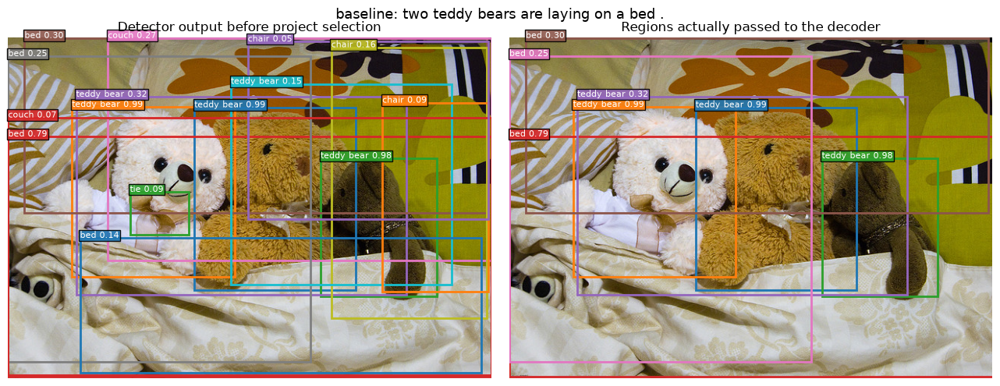

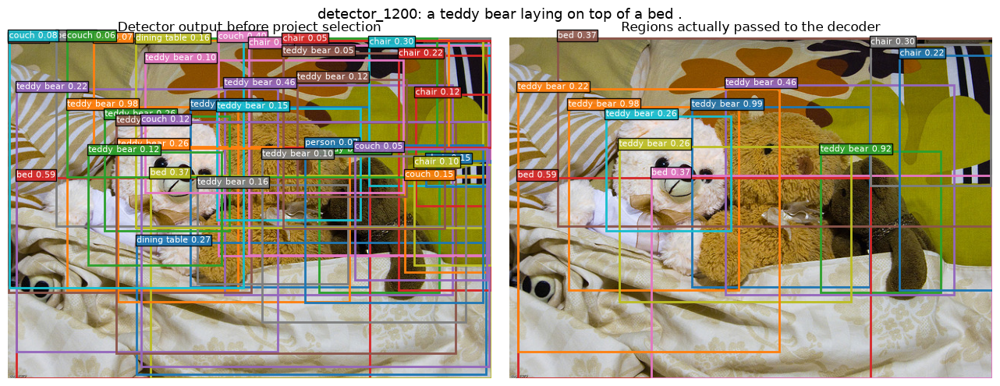

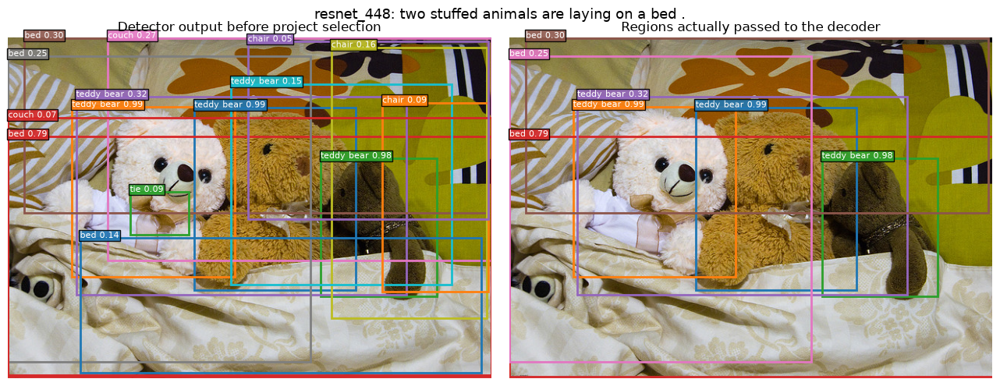

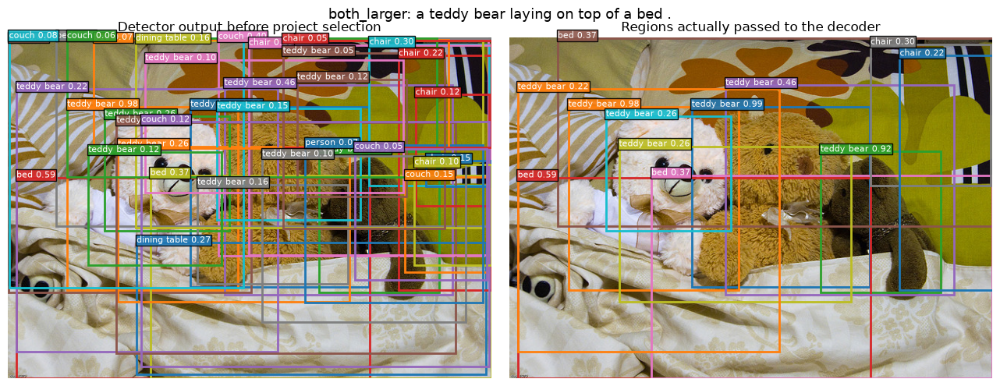

Saved comparison, captions, detector boxes, timing and figures to: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\resolution_inference_20261126\runs\000000113403_20261126T060700_825165Z


a teddy bear laying on top of a bed . | 0.89 seconds


,Mode,ResNet input,Detector H x W,Selected regions,Selected teddy boxes,Selected bear boxes,Caption,Seconds,Peak GPU GiB
0,baseline,224,800 x 1135,7,4,0,two teddy bears are laying on a bed .,0.93,0.76
1,detector_1200,224,1200 x 1702,12,7,0,a teddy bear laying on top of a bed .,0.94,1.28
2,resnet_448,448,800 x 1135,7,4,0,two stuffed animals are laying on a bed .,0.94,0.77
3,both_larger,448,1200 x 1702,12,7,0,a teddy bear laying on top of a bed .,0.89,1.29


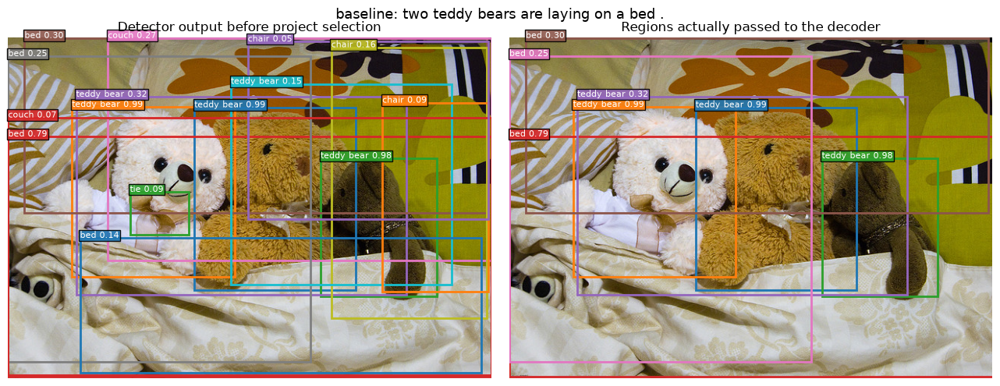

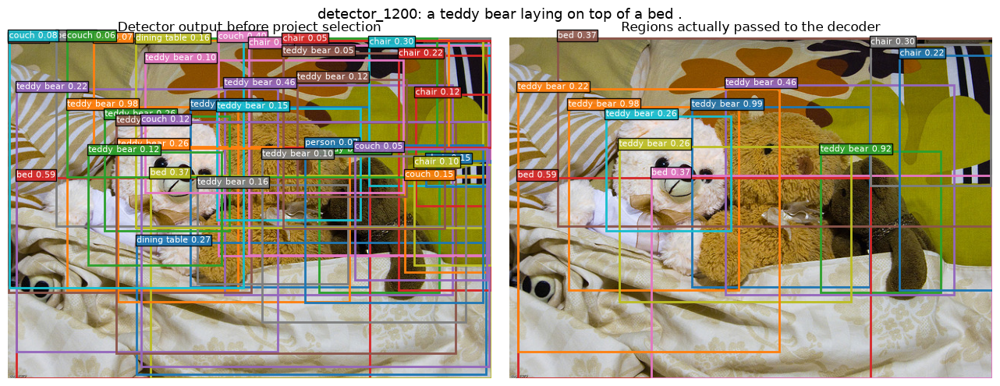

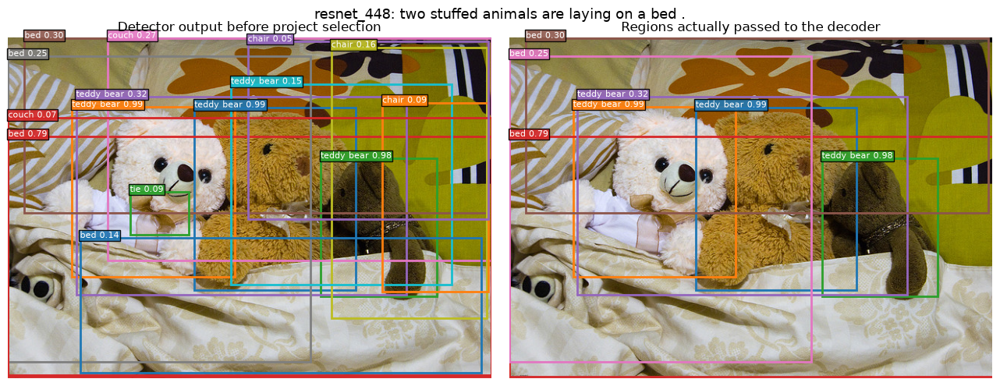

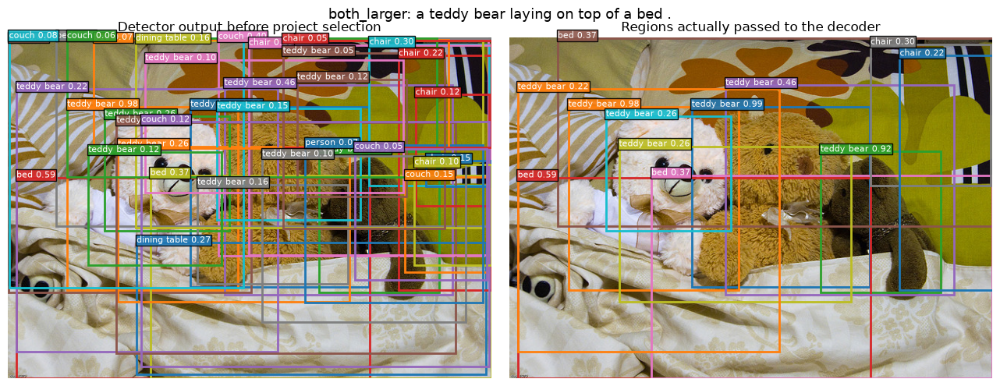

Saved comparison, captions, detector boxes, timing and figures to: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\resolution_inference_20261126\runs\000000113403_20261126T055831_714538Z


In [7]:
# Run this cell again after changing IMAGE_PATH; models stay loaded
output_dir=make_resolution_run_folder(RESULTS_DIR,IMAGE_PATH)
records=[]
for mode in MODES:
    print("Running",mode["name"],flush=True)
    result=run_resolution_case(IMAGE_PATH,mode,model,vocabulary,token_ids,encoders)
    records.append(result)
    save_resolution_results(output_dir,records,weights_sha,loading_seconds)
    print(f"{result['caption']} | {result['total_seconds']:.2f} seconds",flush=True)

display(resolution_table(records))
show_resolution_detections(IMAGE_PATH,records,output_dir)
print("Saved comparison, captions, detector boxes, timing and figures to:",output_dir)


## 5. Optional validation comparison

The default is **off**. Enable `RUN_VALIDATION` to compare all four modes on the same 5000 validation images. Set `VALIDATION_IMAGES=100` for a smaller paired pilot selected with seed 42. This is slower because both CNNs run on each image again. No test images are used.

All original human captions are references. The scorer is the original project implementation: `pycocoevalcap==1.2`, corpus BLEU-1/BLEU-4 on the 0-1 scale, and CIDEr-D on the library's native scale. The original regex tokenizer is applied to predictions and references without vocabulary replacement.

**A pilot score is comparable only across these modes on the same pilot.** CIDEr document frequencies depend on the evaluated reference corpus, so a 100-image score must not be compared directly with the old 5000-image score of 0.9801. Check the full validation set before replacing the default inference settings. Partial predictions are saved every 25 images; rerunning this optional cell starts a new comparison folder.

The exact split and vocabulary metadata are included under `metadata/preparation/`; no prepared caption pickle or old numerical feature cache is needed for this evaluation.


In [8]:
class MetricEvaluator:
    def __init__(self,settings):
        version = package_metadata.version("pycocoevalcap")
        if version != "1.2":
            raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
        self.token_pattern = settings["token_pattern"]
        re.compile(self.token_pattern)
        self.metadata = {
            "package": "pycocoevalcap",
            "version": version,
            "bleu": {
                "implementation": "Bleu(4)",
                "aggregation": "corpus",
                "scale": "0..1; no multiplication by 100",
            },
            "cider_d": {
                "implementation": "Cider(n=4,sigma=6.0)",
                "ngrams": 4,
                "sigma": 6.0,
                "scale": "native score, including the implementation's factor 10; no extra multiplication",
                "document_frequency": "all reference sets in the evaluated split",
            },
            "tokenization": {
                "name": "project_regex_v1",
                "normalization": "NFKC,lowercase,smart quotes,whitespace",
                "token_pattern": self.token_pattern,
                "reference_vocabulary_mapping": False,
                "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
            },
            "source_sha256": {
                name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                for name,cls in [
                    ("bleu",Bleu),
                    ("bleu_scorer",BleuScorer),
                    ("cider",Cider),
                    ("cider_scorer",CiderScorer),
                ]
            },
        }

    def tokenize(self,text):
        text = unicodedata.normalize("NFKC",text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        text = " ".join(text.split())
        return " ".join(re.findall(self.token_pattern,text))

    def score(self,records,expected_ids=None):
        # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
        if len(records) < 2:
            raise ValueError("CIDEr-D needs a corpus with at least two images.")
        gts = {}
        res = {}
        for item in records:
            image_id = int(item["image_id"])
            if image_id in gts:
                raise ValueError(f"Duplicate prediction for image {image_id}")
            references = item["references"]
            if not isinstance(references,list) or not references:
                raise ValueError(f"Missing human references for image {image_id}")
            if not all(isinstance(text,str) and text.strip() for text in references):
                raise ValueError(f"Empty or invalid human reference for image {image_id}")
            if not isinstance(item["prediction"],str):
                raise TypeError("Each prediction must be a string.")
            gts[image_id] = [self.tokenize(text) for text in references]
            if not all(gts[image_id]):
                raise ValueError(f"A reference has no tokens for image {image_id}")
            res[image_id] = [self.tokenize(item["prediction"])]
        if expected_ids is not None:
            expected = [int(image_id) for image_id in expected_ids]
            if len(expected) != len(set(expected)) or set(gts) != set(expected):
                raise ValueError("Predictions do not cover exactly the requested evaluation split.")
        bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
        cider_d,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
        scores = {"bleu1": float(bleu[0]),"bleu4": float(bleu[3]),"cider_d": float(cider_d)}
        if not all(np.isfinite(value) for value in scores.values()):
            raise ValueError("The metric implementation returned a non-finite score.")
        return scores


def check_metrics(evaluator):
    # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
    sentences = [
        "A red bus drives down the road.",
        "Two cats sleep on the green sofa.",
        "A woman holds a yellow umbrella.",
    ]
    records = [
        {"image_id": index,"prediction": text,"references": [text,text]}
        for index,text in enumerate(sentences)
    ]
    exact = evaluator.score(records,expected_ids=range(len(records)))
    assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
    assert abs(exact["cider_d"] - 10) < 1e-6
    unrelated = [
        {**row,"prediction": "unrelated vocabulary never matches anything"} for row in records
    ]
    poor = evaluator.score(unrelated)
    assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
    empty = evaluator.score([{**row,"prediction": ""} for row in records])
    assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
    # These are library corpus scores, not sentence scores averaged by our code.
    gts = {
        row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
    }
    res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
    direct_bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
    direct_cider,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
    assert exact == {
        "bleu1": float(direct_bleu[0]),
        "bleu4": float(direct_bleu[3]),
        "cider_d": float(direct_cider),
    }
    try:
        evaluator.score(records,expected_ids=[0,1,99])
    except ValueError:
        pass
    else:
        raise AssertionError("Incomplete evaluation corpus was accepted.")
    print(
        "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
    )
    return {"exact": exact,"unrelated": poor,"empty_predictions": empty}

In [9]:
if RUN_VALIDATION:
    evaluator=MetricEvaluator(resolution_metric_settings(PROJECT_DIR,vocabulary))
    check_metrics(evaluator)
    validation_results,validation_folder=evaluate_resolution_validation(
        DATA_ROOT,PROJECT_DIR,RESULTS_DIR,VALIDATION_IMAGES,SEED,MODES,
        model,vocabulary,token_ids,encoders,evaluator,weights_sha,
    )
    display(validation_results.sort_values("cider_d",ascending=False))
    print("Saved validation results:",validation_folder)
else:
    print("Validation is off. Set RUN_VALIDATION=True to run the configured paired comparison.")


Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage.
baseline: 25/5000
baseline: 50/5000
baseline: 75/5000
baseline: 100/5000
baseline: 125/5000
baseline: 150/5000
baseline: 175/5000
baseline: 200/5000
baseline: 225/5000
baseline: 250/5000
baseline: 275/5000
baseline: 300/5000
baseline: 325/5000
baseline: 350/5000
baseline: 375/5000
baseline: 400/5000
baseline: 425/5000
baseline: 450/5000
baseline: 475/5000
baseline: 500/5000
baseline: 525/5000
baseline: 550/5000
baseline: 575/5000
baseline: 600/5000
baseline: 625/5000
baseline: 650/5000
baseline: 675/5000
baseline: 700/5000
baseline: 725/5000
baseline: 750/5000
baseline: 775/5000
baseline: 800/5000
baseline: 825/5000
baseline: 850/5000
baseline: 875/5000
baseline: 900/5000
baseline: 925/5000
baseline: 950/5000
baseline: 975/5000
baseline: 1000/5000
baseline: 1025/5000
baseline: 1050/5000
baseline: 1075/5000
baseline: 1100/5000
baseline: 1125/5000
baseline: 1150/5000
baseline: 1175/5000
base

,mode,images,bleu1,bleu4,cider_d,seconds
0,baseline,5000,0.741423,0.316192,0.980339,3663.700517
1,detector_1200,5000,0.738930,0.313161,0.967319,3297.126976
2,resnet_448,5000,0.734776,0.311360,0.951277,2879.076999
3,both_larger,5000,0.729297,0.305034,0.931831,3279.556995


Saved validation results: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\resolution_inference_20261126\runs\validation_5000_seed42_20261126T060712_617052Z


## 6. How to interpret the outcome

- More useful detector regions with better captions would support further testing of higher resolution.
- Three visible teddy-bear regions with a caption saying "two" would point to a caption-counting problem, rather than simply a missing detector box.
- A detection removed by the extra selection stage would motivate a separate threshold/NMS experiment. Those settings are deliberately fixed here.
- More boxes or a better single example is not evidence of an overall quality gain. Use the paired validation section.
- No higher-resolution model has been trained in this notebook. No new checkpoint is claimed. Any later fine-tuning must use a separate experiment folder and the matching preprocessing.

References: [Torchvision Faster R-CNN](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.detection.fasterrcnn_resnet50_fpn.html), [detector resizing implementation](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/transform.py).


## 7. Completed checks on 26 November 2026

The original detector already supplies distinct boxes for all three teddy bears, with scores **0.993, 0.987 and 0.982**. These boxes survive project selection. There is also an extra lower-confidence teddy-bear box, so counting boxes alone is not a reliable count of objects.

The original caption is "two teddy bears are laying on a bed ." The larger detector input gives "a teddy bear laying on top of a bed ." The larger ResNet input gives "two stuffed animals are laying on a bed ." Increasing both inputs gives "a teddy bear laying on top of a bed ." **None of these resolution-only changes fixes the counting example.**

The source photo is 640 x 451 pixels. Even the baseline detector already upsamples it. Enlarging it further does not introduce new original image detail.

The new baseline feature tensors match the original implementation exactly. All four modes ran on the RTX 4060 Laptop GPU with frozen weights and restored detector settings after each call.

### Historical 100-image pilot

The same 100 validation IDs, seed 42, all human references and unchanged decoding were first evaluated:

| Mode | CIDEr-D | BLEU-1 | BLEU-4 |
|---|---:|---:|---:|
| baseline | 0.9981 | 0.7293 | 0.3145 |
| detector_1200 | 0.9982 | 0.7350 | 0.3253 |
| resnet_448 | 1.0116 | 0.7294 | 0.3046 |
| both_larger | 1.0214 | 0.7362 | 0.3083 |

The pilot suggested testing `both_larger`, but it was not a full-validation result or a new test evaluation. Its BLEU-4 was already below baseline.

### Completed full-validation comparison

All four modes were then evaluated on the same 5000 validation images, with identical original references, model weights and decoding settings:

| Mode | CIDEr-D | BLEU-1 | BLEU-4 | Time (seconds) |
|---|---:|---:|---:|---:|
| baseline | 0.98034 | 0.74142 | 0.31619 | 3663.7 |
| detector_1200 | 0.96732 | 0.73893 | 0.31316 | 3297.1 |
| resnet_448 | 0.95128 | 0.73478 | 0.31136 | 2879.1 |
| both_larger | 0.93183 | 0.72930 | 0.30503 | 3279.6 |

**Keep the original baseline preprocessing.** Every larger-input mode scored lower on full-validation CIDEr-D and BLEU-4. The pilot ranking did not hold on the full set. This does not prove that higher-resolution training cannot help; it shows that changing inference resolution with these unchanged weights did not help.

The runs used an RTX 4060 Laptop GPU. These sequential wall-clock times are saved observations, not a controlled repeated speed benchmark. The full-validation baseline is a new rerun; it does not replace the historical submission score of about 0.9801. No test images or training updates were used.

Do not compare absolute CIDEr-D values between the 100-image and 5000-image tables: their reference corpora, and therefore document frequencies, differ. Compare modes within each table. A later counting experiment should evaluate quantity errors explicitly and adapt the decoder with appropriate examples; three detector boxes alone do not guarantee that the caption will say "three".
